# Búsqueda automática de hiperparámetros

Las pruebas T01–T08 se entrenaron en **CPU**. En la tabla comparativa, C1–C4 se entrenaron en **GPU** y C5–C8 en CPU, así que los tiempos no son comparables; la comparación se hace por la pérdida y el acierto de validación.

In [1]:
import csv
import itertools
import random

import matplotlib.pyplot as plt
import torch.nn as nn
from matplotlib.patches import Patch

from utilidades import ejecutar_configuracion, device

print(f'Usando dispositivo: {device}')

Usando dispositivo: cpu


## Espacio de búsqueda

In [2]:
espacio_busqueda = {
    'lr': [0.001, 0.0005, 0.0001],
    'tam_lote': [64, 128],
    'filtros': [(16, 32, 64), (32, 64, 128)],
    'neuronas_fc': [(128,), (256, 128)],
    'p_dropout': [0.25, 0.5],
}

combinaciones = [dict(zip(espacio_busqueda.keys(), valores))
                 for valores in itertools.product(*espacio_busqueda.values())]
print(f'Combinaciones posibles: {len(combinaciones)}')

Combinaciones posibles: 48


## Selección aleatoria de configuraciones

In [3]:
num_pruebas = 8
epocas_max = 10
paciencia = 3

configuraciones_tuning = random.Random(42).sample(combinaciones, num_pruebas)
nombres_tuning = [f'T{numero:02d}' for numero in range(1, num_pruebas + 1)]

for nombre, configuracion in zip(nombres_tuning, configuraciones_tuning):
    print(f'{nombre} | {configuracion}')

T01 | {'lr': 0.0001, 'tam_lote': 128, 'filtros': (16, 32, 64), 'neuronas_fc': (128,), 'p_dropout': 0.25}
T02 | {'lr': 0.001, 'tam_lote': 64, 'filtros': (32, 64, 128), 'neuronas_fc': (256, 128), 'p_dropout': 0.5}
T03 | {'lr': 0.001, 'tam_lote': 64, 'filtros': (16, 32, 64), 'neuronas_fc': (128,), 'p_dropout': 0.5}
T04 | {'lr': 0.0005, 'tam_lote': 64, 'filtros': (16, 32, 64), 'neuronas_fc': (128,), 'p_dropout': 0.5}
T05 | {'lr': 0.001, 'tam_lote': 128, 'filtros': (32, 64, 128), 'neuronas_fc': (256, 128), 'p_dropout': 0.5}
T06 | {'lr': 0.001, 'tam_lote': 128, 'filtros': (32, 64, 128), 'neuronas_fc': (256, 128), 'p_dropout': 0.25}
T07 | {'lr': 0.001, 'tam_lote': 128, 'filtros': (16, 32, 64), 'neuronas_fc': (128,), 'p_dropout': 0.25}
T08 | {'lr': 0.001, 'tam_lote': 64, 'filtros': (32, 64, 128), 'neuronas_fc': (256, 128), 'p_dropout': 0.25}


## Entrenamiento de las configuraciones

Entrenando T01: {'lr': 0.0001, 'tam_lote': 128, 'filtros': (16, 32, 64), 'neuronas_fc': (128,), 'p_dropout': 0.25}
Época [ 1/10] | Train Loss: 0.1542 | Train Acc: 0.9628 | Val Loss: 0.0216 | Val Acc: 0.9952 *
Época [ 2/10] | Train Loss: 0.0266 | Train Acc: 0.9942 | Val Loss: 0.0129 | Val Acc: 0.9972 *
Época [ 3/10] | Train Loss: 0.0182 | Train Acc: 0.9963 | Val Loss: 0.0120 | Val Acc: 0.9972 *
Época [ 4/10] | Train Loss: 0.0141 | Train Acc: 0.9974 | Val Loss: 0.0099 | Val Acc: 0.9980 *
Época [ 5/10] | Train Loss: 0.0092 | Train Acc: 0.9982 | Val Loss: 0.0088 | Val Acc: 0.9983 *
Época [ 6/10] | Train Loss: 0.0067 | Train Acc: 0.9986 | Val Loss: 0.0085 | Val Acc: 0.9983 *
Época [ 7/10] | Train Loss: 0.0044 | Train Acc: 0.9991 | Val Loss: 0.0086 | Val Acc: 0.9983 
Época [ 8/10] | Train Loss: 0.0042 | Train Acc: 0.9993 | Val Loss: 0.0124 | Val Acc: 0.9972 
Época [ 9/10] | Train Loss: 0.0026 | Train Acc: 0.9994 | Val Loss: 0.0096 | Val Acc: 0.9989 
Parada anticipada: 3 épocas sin mejorar la

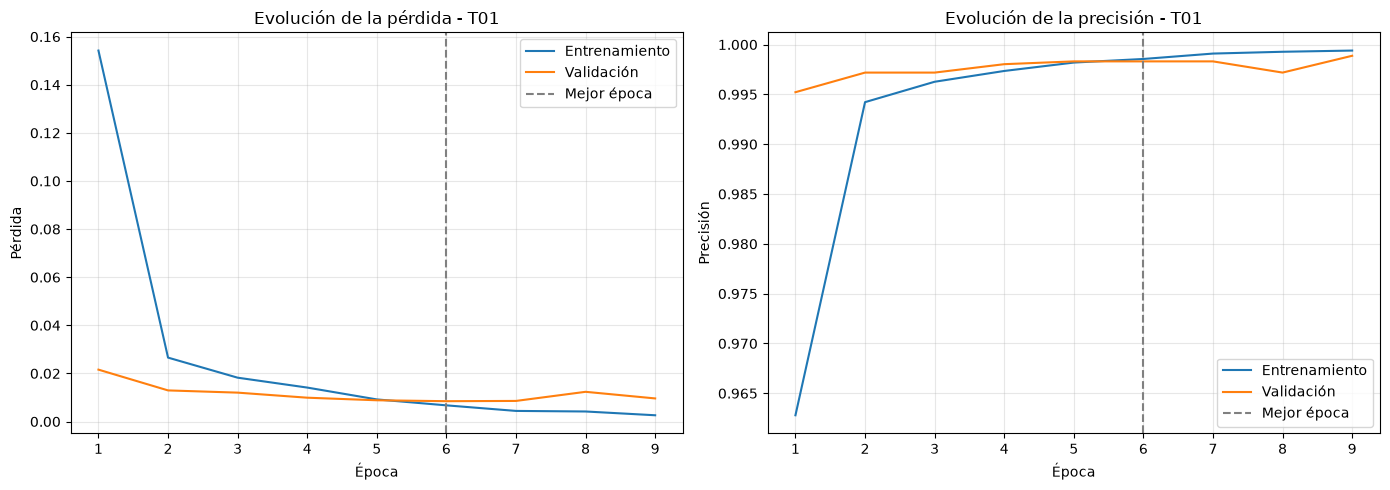

Entrenando T02: {'lr': 0.001, 'tam_lote': 64, 'filtros': (32, 64, 128), 'neuronas_fc': (256, 128), 'p_dropout': 0.5}
Época [ 1/10] | Train Loss: 0.4149 | Train Acc: 0.8866 | Val Loss: 0.0251 | Val Acc: 0.9941 *
Época [ 2/10] | Train Loss: 0.0830 | Train Acc: 0.9799 | Val Loss: 0.0199 | Val Acc: 0.9941 *
Época [ 3/10] | Train Loss: 0.0656 | Train Acc: 0.9839 | Val Loss: 0.0201 | Val Acc: 0.9961 
Época [ 4/10] | Train Loss: 0.0542 | Train Acc: 0.9881 | Val Loss: 0.0144 | Val Acc: 0.9958 *
Época [ 5/10] | Train Loss: 0.0538 | Train Acc: 0.9865 | Val Loss: 0.0182 | Val Acc: 0.9961 
Época [ 6/10] | Train Loss: 0.0447 | Train Acc: 0.9902 | Val Loss: 0.0155 | Val Acc: 0.9963 
Época [ 7/10] | Train Loss: 0.0467 | Train Acc: 0.9902 | Val Loss: 0.0121 | Val Acc: 0.9958 *
Época [ 8/10] | Train Loss: 0.0293 | Train Acc: 0.9936 | Val Loss: 0.0108 | Val Acc: 0.9983 *
Época [ 9/10] | Train Loss: 0.0352 | Train Acc: 0.9924 | Val Loss: 0.0127 | Val Acc: 0.9966 
Época [10/10] | Train Loss: 0.0326 | Trai

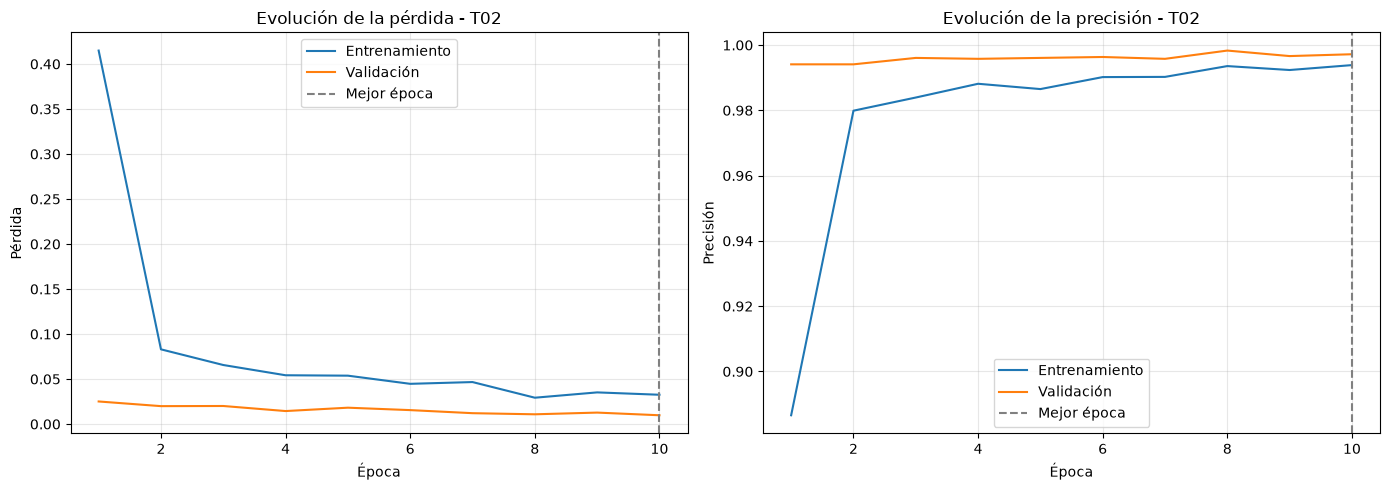

Entrenando T03: {'lr': 0.001, 'tam_lote': 64, 'filtros': (16, 32, 64), 'neuronas_fc': (128,), 'p_dropout': 0.5}
Época [ 1/10] | Train Loss: 0.2617 | Train Acc: 0.9335 | Val Loss: 0.0248 | Val Acc: 0.9947 *
Época [ 2/10] | Train Loss: 0.0595 | Train Acc: 0.9863 | Val Loss: 0.0122 | Val Acc: 0.9963 *
Época [ 3/10] | Train Loss: 0.0429 | Train Acc: 0.9902 | Val Loss: 0.0158 | Val Acc: 0.9947 
Época [ 4/10] | Train Loss: 0.0409 | Train Acc: 0.9903 | Val Loss: 0.0187 | Val Acc: 0.9961 
Época [ 5/10] | Train Loss: 0.0415 | Train Acc: 0.9898 | Val Loss: 0.0092 | Val Acc: 0.9980 *
Época [ 6/10] | Train Loss: 0.0312 | Train Acc: 0.9924 | Val Loss: 0.0150 | Val Acc: 0.9969 
Época [ 7/10] | Train Loss: 0.0282 | Train Acc: 0.9924 | Val Loss: 0.0112 | Val Acc: 0.9980 
Época [ 8/10] | Train Loss: 0.0252 | Train Acc: 0.9945 | Val Loss: 0.0481 | Val Acc: 0.9902 
Parada anticipada: 3 épocas sin mejorar la pérdida de validación
Mejor época: 5 | Tiempo total: 1022.8 segundos


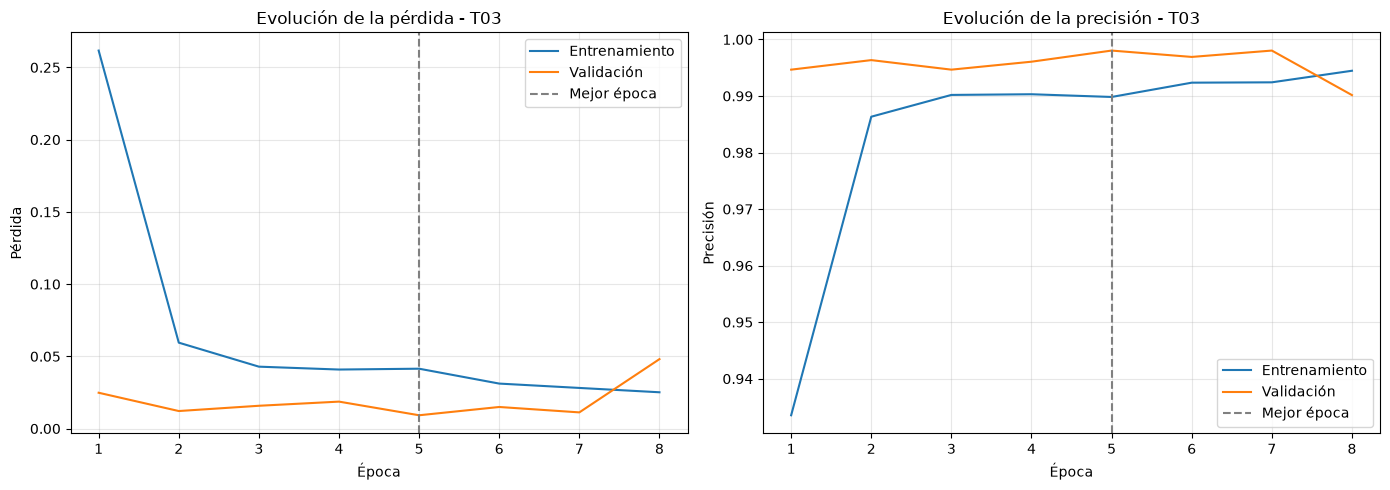

Entrenando T04: {'lr': 0.0005, 'tam_lote': 64, 'filtros': (16, 32, 64), 'neuronas_fc': (128,), 'p_dropout': 0.5}
Época [ 1/10] | Train Loss: 0.1694 | Train Acc: 0.9548 | Val Loss: 0.0222 | Val Acc: 0.9935 *
Época [ 2/10] | Train Loss: 0.0373 | Train Acc: 0.9911 | Val Loss: 0.0110 | Val Acc: 0.9972 *
Época [ 3/10] | Train Loss: 0.0297 | Train Acc: 0.9937 | Val Loss: 0.0111 | Val Acc: 0.9972 
Época [ 4/10] | Train Loss: 0.0283 | Train Acc: 0.9936 | Val Loss: 0.0134 | Val Acc: 0.9975 
Época [ 5/10] | Train Loss: 0.0258 | Train Acc: 0.9939 | Val Loss: 0.0123 | Val Acc: 0.9978 
Parada anticipada: 3 épocas sin mejorar la pérdida de validación
Mejor época: 2 | Tiempo total: 642.3 segundos


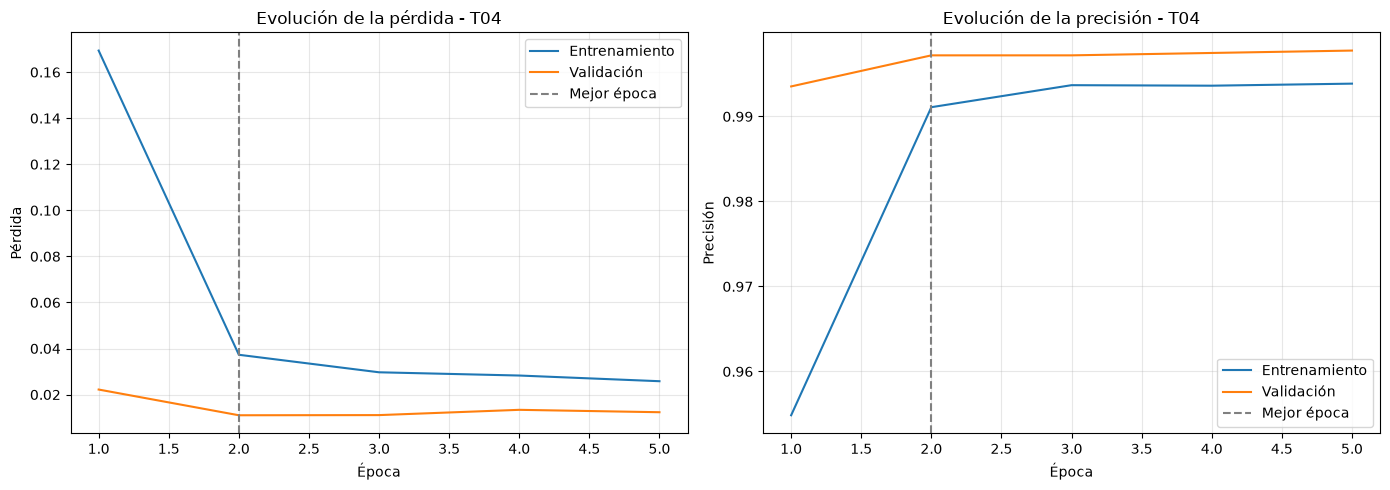

Entrenando T05: {'lr': 0.001, 'tam_lote': 128, 'filtros': (32, 64, 128), 'neuronas_fc': (256, 128), 'p_dropout': 0.5}
Época [ 1/10] | Train Loss: 0.5232 | Train Acc: 0.8603 | Val Loss: 0.0367 | Val Acc: 0.9904 *
Época [ 2/10] | Train Loss: 0.0756 | Train Acc: 0.9810 | Val Loss: 0.0166 | Val Acc: 0.9941 *
Época [ 3/10] | Train Loss: 0.0519 | Train Acc: 0.9862 | Val Loss: 0.0167 | Val Acc: 0.9961 
Época [ 4/10] | Train Loss: 0.0485 | Train Acc: 0.9871 | Val Loss: 0.0168 | Val Acc: 0.9949 
Época [ 5/10] | Train Loss: 0.0474 | Train Acc: 0.9900 | Val Loss: 0.0147 | Val Acc: 0.9955 *
Época [ 6/10] | Train Loss: 0.0398 | Train Acc: 0.9913 | Val Loss: 0.0153 | Val Acc: 0.9955 
Época [ 7/10] | Train Loss: 0.0312 | Train Acc: 0.9930 | Val Loss: 0.0171 | Val Acc: 0.9961 
Época [ 8/10] | Train Loss: 0.0347 | Train Acc: 0.9922 | Val Loss: 0.0088 | Val Acc: 0.9980 *
Época [ 9/10] | Train Loss: 0.0300 | Train Acc: 0.9934 | Val Loss: 0.0108 | Val Acc: 0.9969 
Época [10/10] | Train Loss: 0.0229 | Trai

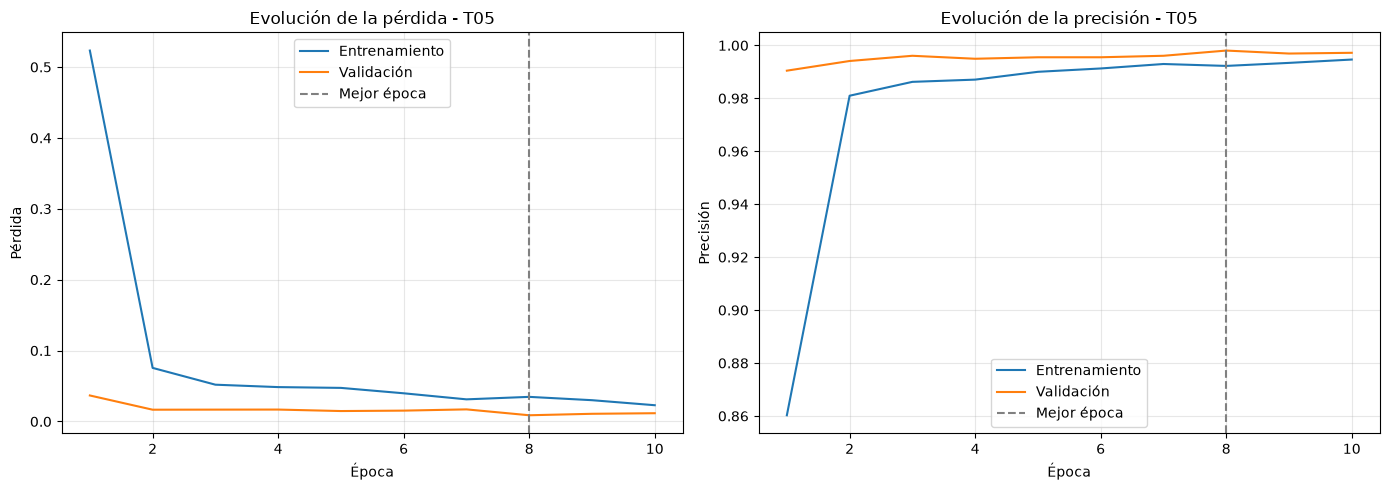

Entrenando T06: {'lr': 0.001, 'tam_lote': 128, 'filtros': (32, 64, 128), 'neuronas_fc': (256, 128), 'p_dropout': 0.25}
Época [ 1/10] | Train Loss: 0.2870 | Train Acc: 0.9266 | Val Loss: 0.0209 | Val Acc: 0.9955 *
Época [ 2/10] | Train Loss: 0.0330 | Train Acc: 0.9928 | Val Loss: 0.0164 | Val Acc: 0.9947 *
Época [ 3/10] | Train Loss: 0.0278 | Train Acc: 0.9940 | Val Loss: 0.0170 | Val Acc: 0.9958 
Época [ 4/10] | Train Loss: 0.0229 | Train Acc: 0.9948 | Val Loss: 0.0124 | Val Acc: 0.9966 *
Época [ 5/10] | Train Loss: 0.0209 | Train Acc: 0.9949 | Val Loss: 0.0104 | Val Acc: 0.9975 *
Época [ 6/10] | Train Loss: 0.0199 | Train Acc: 0.9951 | Val Loss: 0.0137 | Val Acc: 0.9966 
Época [ 7/10] | Train Loss: 0.0185 | Train Acc: 0.9958 | Val Loss: 0.0131 | Val Acc: 0.9963 
Época [ 8/10] | Train Loss: 0.0129 | Train Acc: 0.9971 | Val Loss: 0.0064 | Val Acc: 0.9980 *
Época [ 9/10] | Train Loss: 0.0123 | Train Acc: 0.9972 | Val Loss: 0.0070 | Val Acc: 0.9975 
Época [10/10] | Train Loss: 0.0140 | Tr

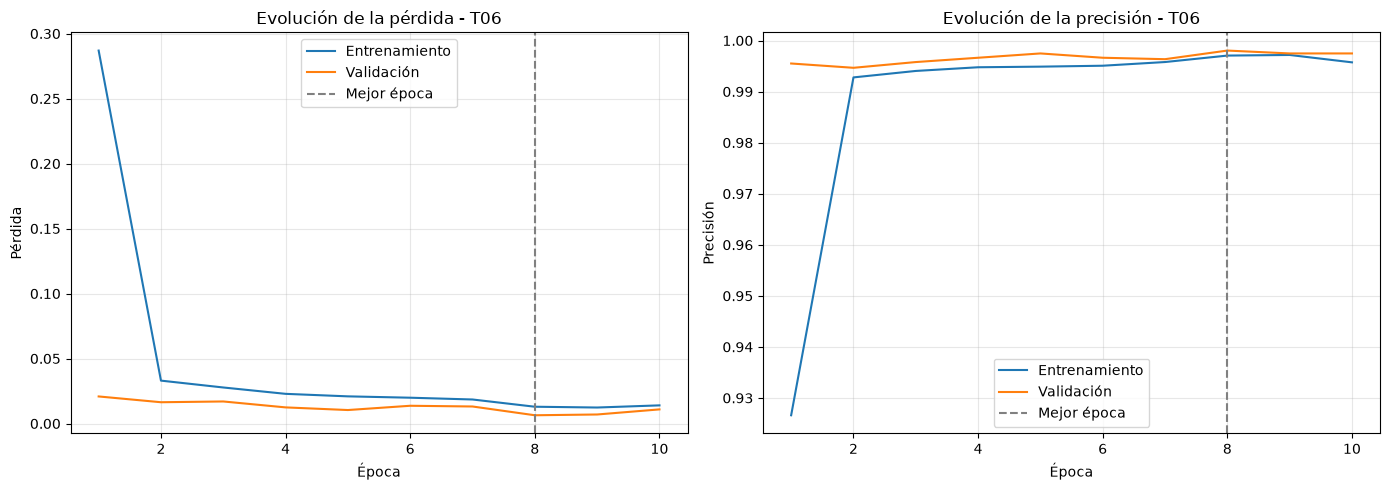

Entrenando T07: {'lr': 0.001, 'tam_lote': 128, 'filtros': (16, 32, 64), 'neuronas_fc': (128,), 'p_dropout': 0.25}
Época [ 1/10] | Train Loss: 0.2920 | Train Acc: 0.9338 | Val Loss: 0.0254 | Val Acc: 0.9927 *
Época [ 2/10] | Train Loss: 0.0325 | Train Acc: 0.9929 | Val Loss: 0.0143 | Val Acc: 0.9958 *
Época [ 3/10] | Train Loss: 0.0223 | Train Acc: 0.9951 | Val Loss: 0.0155 | Val Acc: 0.9952 
Época [ 4/10] | Train Loss: 0.0174 | Train Acc: 0.9963 | Val Loss: 0.0102 | Val Acc: 0.9963 *
Época [ 5/10] | Train Loss: 0.0165 | Train Acc: 0.9964 | Val Loss: 0.0107 | Val Acc: 0.9966 
Época [ 6/10] | Train Loss: 0.0112 | Train Acc: 0.9977 | Val Loss: 0.0089 | Val Acc: 0.9975 *
Época [ 7/10] | Train Loss: 0.0089 | Train Acc: 0.9979 | Val Loss: 0.0068 | Val Acc: 0.9983 *
Época [ 8/10] | Train Loss: 0.0099 | Train Acc: 0.9976 | Val Loss: 0.0160 | Val Acc: 0.9969 
Época [ 9/10] | Train Loss: 0.0087 | Train Acc: 0.9975 | Val Loss: 0.0098 | Val Acc: 0.9978 
Época [10/10] | Train Loss: 0.0070 | Train A

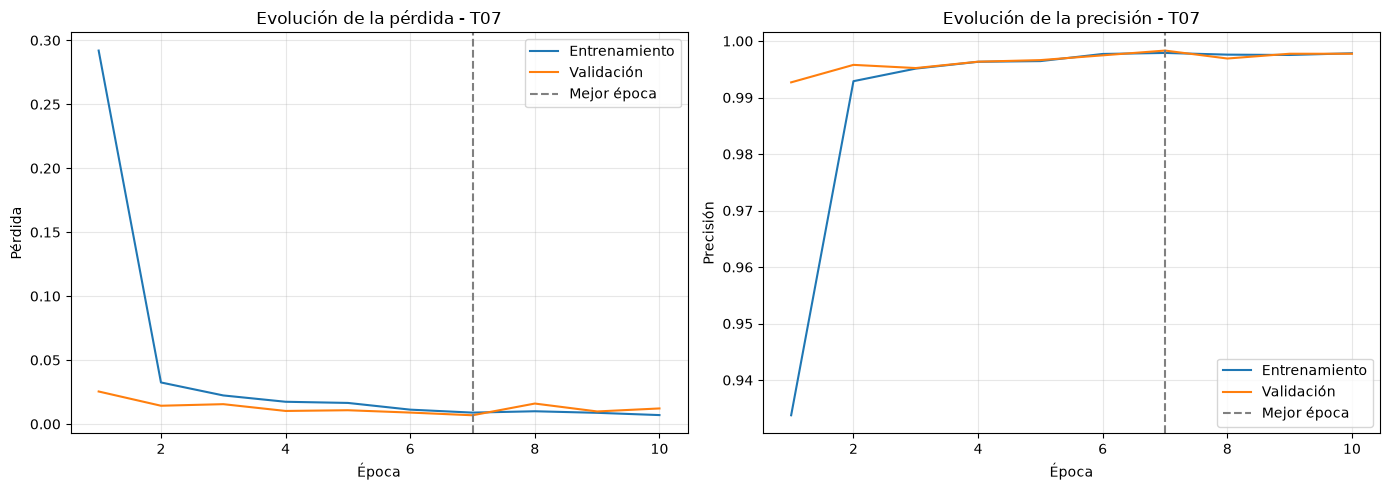

Entrenando T08: {'lr': 0.001, 'tam_lote': 64, 'filtros': (32, 64, 128), 'neuronas_fc': (256, 128), 'p_dropout': 0.25}
Época [ 1/10] | Train Loss: 0.2466 | Train Acc: 0.9409 | Val Loss: 0.0154 | Val Acc: 0.9961 *
Época [ 2/10] | Train Loss: 0.0393 | Train Acc: 0.9908 | Val Loss: 0.0146 | Val Acc: 0.9944 *
Época [ 3/10] | Train Loss: 0.0295 | Train Acc: 0.9934 | Val Loss: 0.0117 | Val Acc: 0.9966 *
Época [ 4/10] | Train Loss: 0.0243 | Train Acc: 0.9942 | Val Loss: 0.0101 | Val Acc: 0.9966 *
Época [ 5/10] | Train Loss: 0.0255 | Train Acc: 0.9942 | Val Loss: 0.0180 | Val Acc: 0.9952 
Época [ 6/10] | Train Loss: 0.0237 | Train Acc: 0.9945 | Val Loss: 0.0158 | Val Acc: 0.9963 
Época [ 7/10] | Train Loss: 0.0238 | Train Acc: 0.9945 | Val Loss: 0.0112 | Val Acc: 0.9966 
Parada anticipada: 3 épocas sin mejorar la pérdida de validación
Mejor época: 4 | Tiempo total: 2286.4 segundos


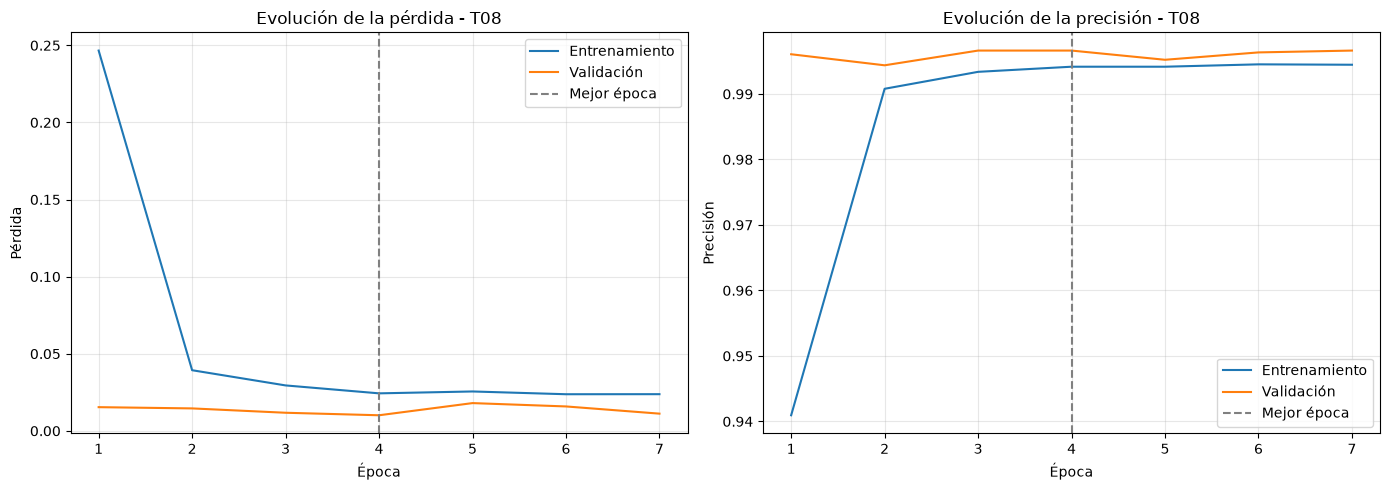

In [4]:
with open('resultados.csv', encoding='utf-8') as fichero:
    ya_entrenadas = {fila['configuracion'] for fila in csv.DictReader(fichero)}

for nombre, configuracion in zip(nombres_tuning, configuraciones_tuning):
    if nombre in ya_entrenadas:
        print(f'{nombre} ya está en resultados.csv, se omite')
        continue
    print(f'Entrenando {nombre}: {configuracion}')
    ejecutar_configuracion(nombre, activacion=nn.LeakyReLU, epocas_max=epocas_max, paciencia=paciencia,
                           **configuracion)

## Resultados ordenados por pérdida de validación

In [5]:
configuraciones_manuales = [f'C{numero}' for numero in range(1, 9)]

with open('resultados.csv', encoding='utf-8') as fichero:
    filas = [fila for fila in csv.DictReader(fichero)
             if fila['configuracion'] in configuraciones_manuales + nombres_tuning]
filas.sort(key=lambda fila: float(fila['perdida_val']))

print(f'{"Config":6s} | {"Búsqueda":10s} | {"Loss val":8s} | {"Acc val":7s} | {"Épocas":6s} | {"Mejor":5s} | {"Tiempo (s)":10s} | {"Dispositivo":11s}')
for fila in filas:
    tipo = 'automática' if fila['configuracion'] in nombres_tuning else 'manual'
    print(f'{fila["configuracion"]:6s} | {tipo:10s} | {fila["perdida_val"]:8s} | {fila["acc_val"]:7s} | '
          f'{fila["epocas_entrenadas"]:6s} | {fila["mejor_epoca"]:5s} | {fila["tiempo_segundos"]:10s} | {fila["dispositivo"]:11s}')

Config | Búsqueda   | Loss val | Acc val | Épocas | Mejor | Tiempo (s) | Dispositivo
T06    | automática | 0.0064   | 0.998   | 10     | 8     | 3269.7     | CPU        
C8     | manual     | 0.0067   | 0.9983  | 17     | 12    | 2818.1     | CPU        
T07    | automática | 0.0068   | 0.9983  | 10     | 7     | 1274.0     | CPU        
C6     | manual     | 0.0085   | 0.9983  | 15     | 10    | 2073.6     | CPU        
T01    | automática | 0.0085   | 0.9983  | 9      | 6     | 1600.1     | CPU        
T05    | automática | 0.0088   | 0.998   | 10     | 8     | 3323.7     | CPU        
C5     | manual     | 0.0089   | 0.9978  | 13     | 8     | 5015.1     | CPU        
C7     | manual     | 0.0089   | 0.9983  | 10     | 5     | 1245.7     | CPU        
C3     | manual     | 0.009    | 0.9975  | 8      | 3     | 173.2      | GPU        
C2     | manual     | 0.0091   | 0.998   | 12     | 7     | 253.3      | GPU        
T03    | automática | 0.0092   | 0.998   | 8      | 5     | 1022.

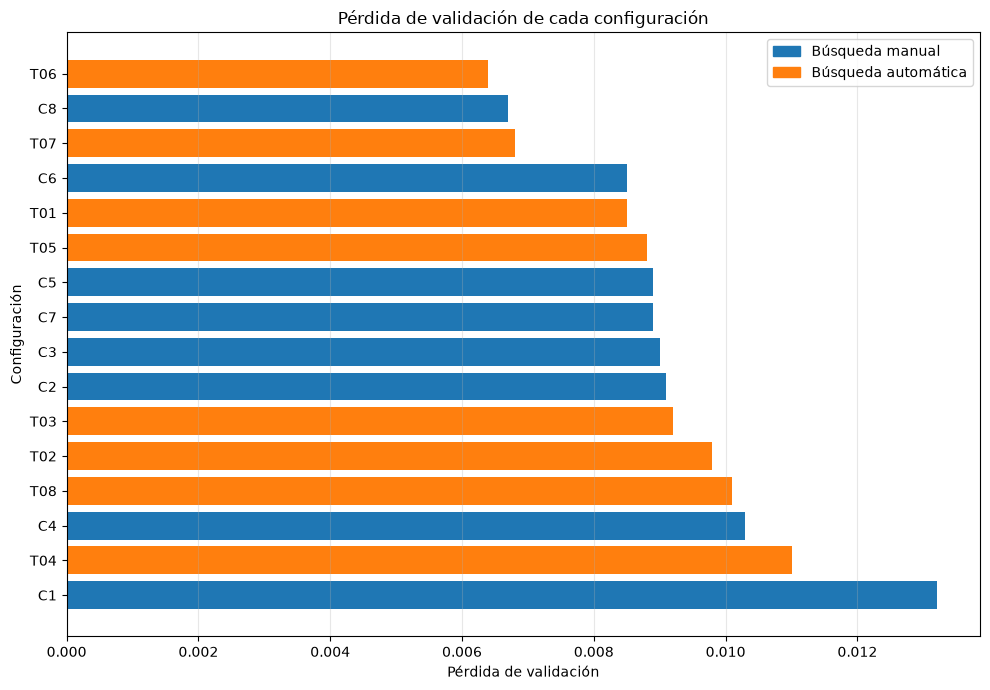

In [6]:
colores = ['tab:orange' if fila['configuracion'] in nombres_tuning else 'tab:blue' for fila in filas]

plt.figure(figsize=(10, 7))
plt.barh([fila['configuracion'] for fila in filas], [float(fila['perdida_val']) for fila in filas], color=colores)
plt.gca().invert_yaxis()
plt.title('Pérdida de validación de cada configuración')
plt.xlabel('Pérdida de validación')
plt.ylabel('Configuración')
plt.legend(handles=[Patch(color='tab:blue', label='Búsqueda manual'),
                    Patch(color='tab:orange', label='Búsqueda automática')])
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('graficas/comparacion_tuning.png', dpi=120)
plt.show()

## Mejor configuración de cada búsqueda

In [7]:
mejor_manual = min((fila for fila in filas if fila['configuracion'] in configuraciones_manuales),
                   key=lambda fila: float(fila['perdida_val']))
mejor_tuning = min((fila for fila in filas if fila['configuracion'] in nombres_tuning),
                   key=lambda fila: float(fila['perdida_val']))

for titulo, fila in [('Mejor manual', mejor_manual), ('Mejor automática', mejor_tuning)]:
    print(f'{titulo}: {fila["configuracion"]} | loss val: {fila["perdida_val"]} | acc val: {fila["acc_val"]}')
    print(f'    {fila["hiperparametros"]}')

Mejor manual: C8 | loss val: 0.0067 | acc val: 0.9983
    tam_imagen=128; tam_lote=64; lr=0.001; filtros=(16, 32, 64); neuronas_fc=(256, 128); activacion=LeakyReLU; p_dropout=0.5; aumentado=False; pesos_clase=False
Mejor automática: T06 | loss val: 0.0064 | acc val: 0.998
    tam_imagen=128; tam_lote=128; lr=0.001; filtros=(32, 64, 128); neuronas_fc=(256, 128); activacion=LeakyReLU; p_dropout=0.25; aumentado=False; pesos_clase=False
